
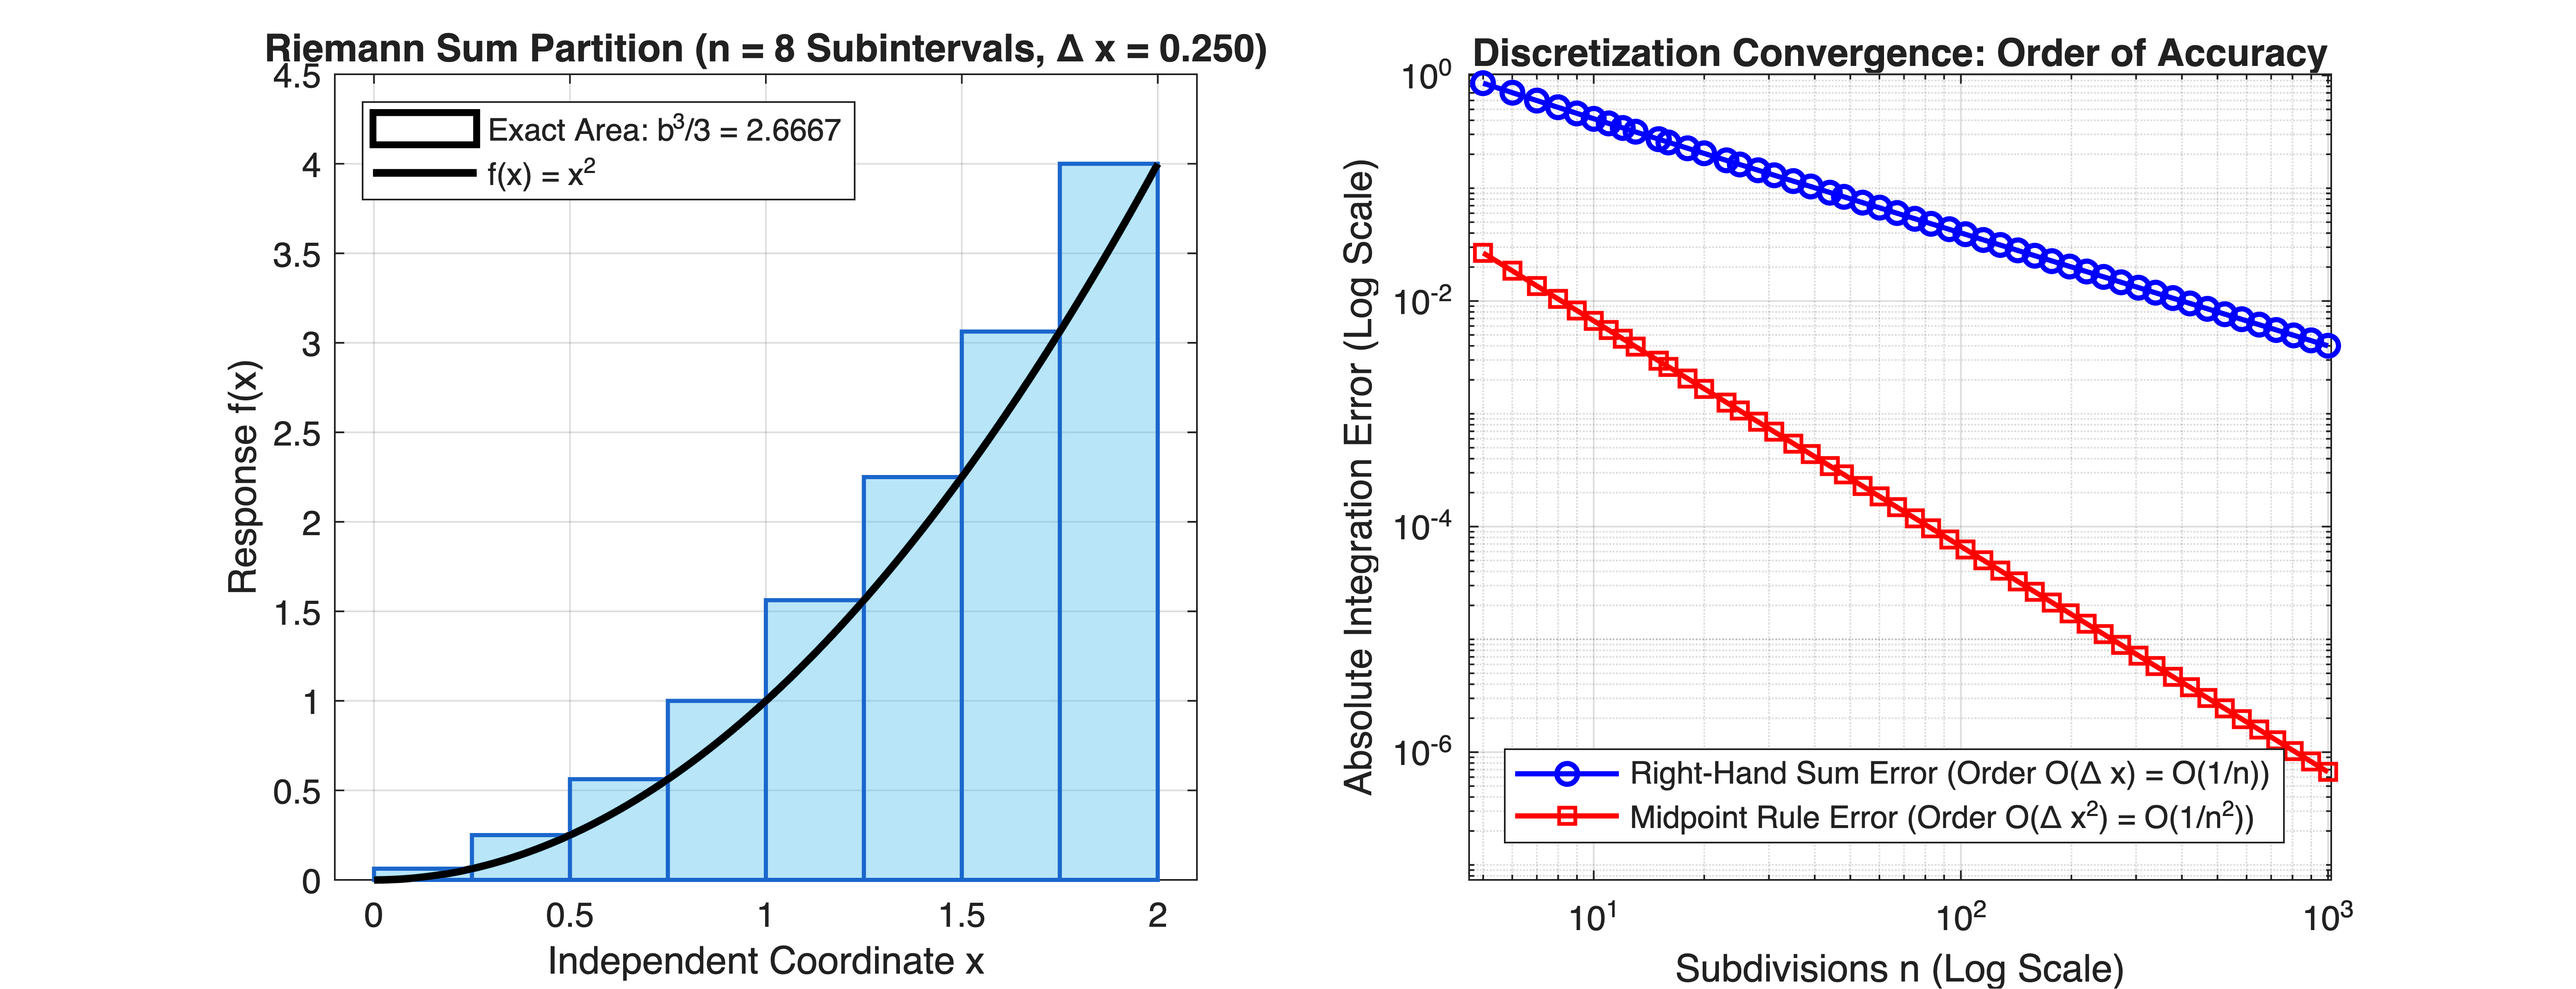

In [1]:
%% MIT 18.01 Lecture 18: Definite Integrals & Riemann Sum Discretization
% Mathematical Tool Application: Used for numerical integration solver design
% (Forward/Backward Euler, Trapezoidal), discrete sensor dead-reckoning accumulation,
% and time-weighted cost function evaluation in optimal control.


clear; clc; close all;


%% Part 1: Geometric Convergence of Riemann Sums (f(x) = x^2, a=0, b=2)
f_parabola = @(x) x.^2;
a_bound = 0.0;
b_bound = 2.0;
exact_integral = (b_bound^3) / 3.0; % Integral of x^2 from 0 to b is b^3 / 3


% Visualization of Right-Hand Riemann Sum with n = 8
n_demo = 8;
dx_demo = (b_bound - a_bound) / n_demo;
x_edges = linspace(a_bound, b_bound, n_demo + 1);


figure('Color', 'w', 'Position', [100, 100, 1250, 480]);


subplot(1, 2, 1);
x_smooth = linspace(a_bound, b_bound, 400);
plot(x_smooth, f_parabola(x_smooth), 'k-', 'LineWidth', 2.2, 'DisplayName', 'f(x) = x^2'); hold on;


% Draw Riemann Rectangles (Right-endpoint rule)
for i = 1:n_demo
    x_left = x_edges(i);
    x_right = x_edges(i+1);
    y_rect = f_parabola(x_right);

    % Draw rectangle boundary and patch
    patch([x_left, x_right, x_right, x_left], [0, 0, y_rect, y_rect], ...
          [0.3, 0.75, 0.93], 'FaceAlpha', 0.4, 'EdgeColor', [0.1, 0.4, 0.8], ...
          'LineWidth', 1.2, 'HandleVisibility', 'off');
end


% Re-plot target curve and exact area
area(x_smooth, f_parabola(x_smooth), 'FaceColor', 'none', 'EdgeColor', 'k', 'LineWidth', 2.0, ...
    'DisplayName', sprintf('Exact Area: b^3/3 = %.4f', exact_integral));


grid on;
xlim([a_bound - 0.1, b_bound + 0.1]); ylim([0, 4.5]);
xlabel('Independent Coordinate x');
ylabel('Response f(x)');
title(sprintf('Riemann Sum Partition (n = %d Subintervals, \\Delta x = %.3f)', n_demo, dx_demo));
legend('Location', 'northwest');


%% Subplot 2: Truncation Error Decay vs. Subinterval Count n
subplot(1, 2, 2);
n_sweep = round(logspace(0.7, 3.0, 50));
riemann_right_errors = zeros(size(n_sweep));
riemann_midpoint_errors = zeros(size(n_sweep));


for k = 1:length(n_sweep)
    n_curr = n_sweep(k);
    dx_curr = (b_bound - a_bound) / n_curr;

    % Right Riemann sum
    x_r = linspace(a_bound + dx_curr, b_bound, n_curr);
    r_sum_right = sum(f_parabola(x_r)) * dx_curr;
    riemann_right_errors(k) = abs(r_sum_right - exact_integral);

    % Midpoint Riemann sum
    x_mid = linspace(a_bound + dx_curr/2, b_bound - dx_curr/2, n_curr);
    r_sum_mid = sum(f_parabola(x_mid)) * dx_curr;
    riemann_midpoint_errors(k) = abs(r_sum_mid - exact_integral);
end


loglog(n_sweep, riemann_right_errors, 'b-o', 'LineWidth', 1.5, ...
    'DisplayName', 'Right-Hand Sum Error (Order O(\Delta x) = O(1/n))'); hold on;
loglog(n_sweep, riemann_midpoint_errors, 'r-s', 'LineWidth', 1.5, ...
    'DisplayName', 'Midpoint Rule Error (Order O(\Delta x^2) = O(1/n^2))');


grid on;
xlabel('Subdivisions n (Log Scale)');
ylabel('Absolute Integration Error (Log Scale)');
title('Discretization Convergence: Order of Accuracy');
legend('Location', 'northeast');


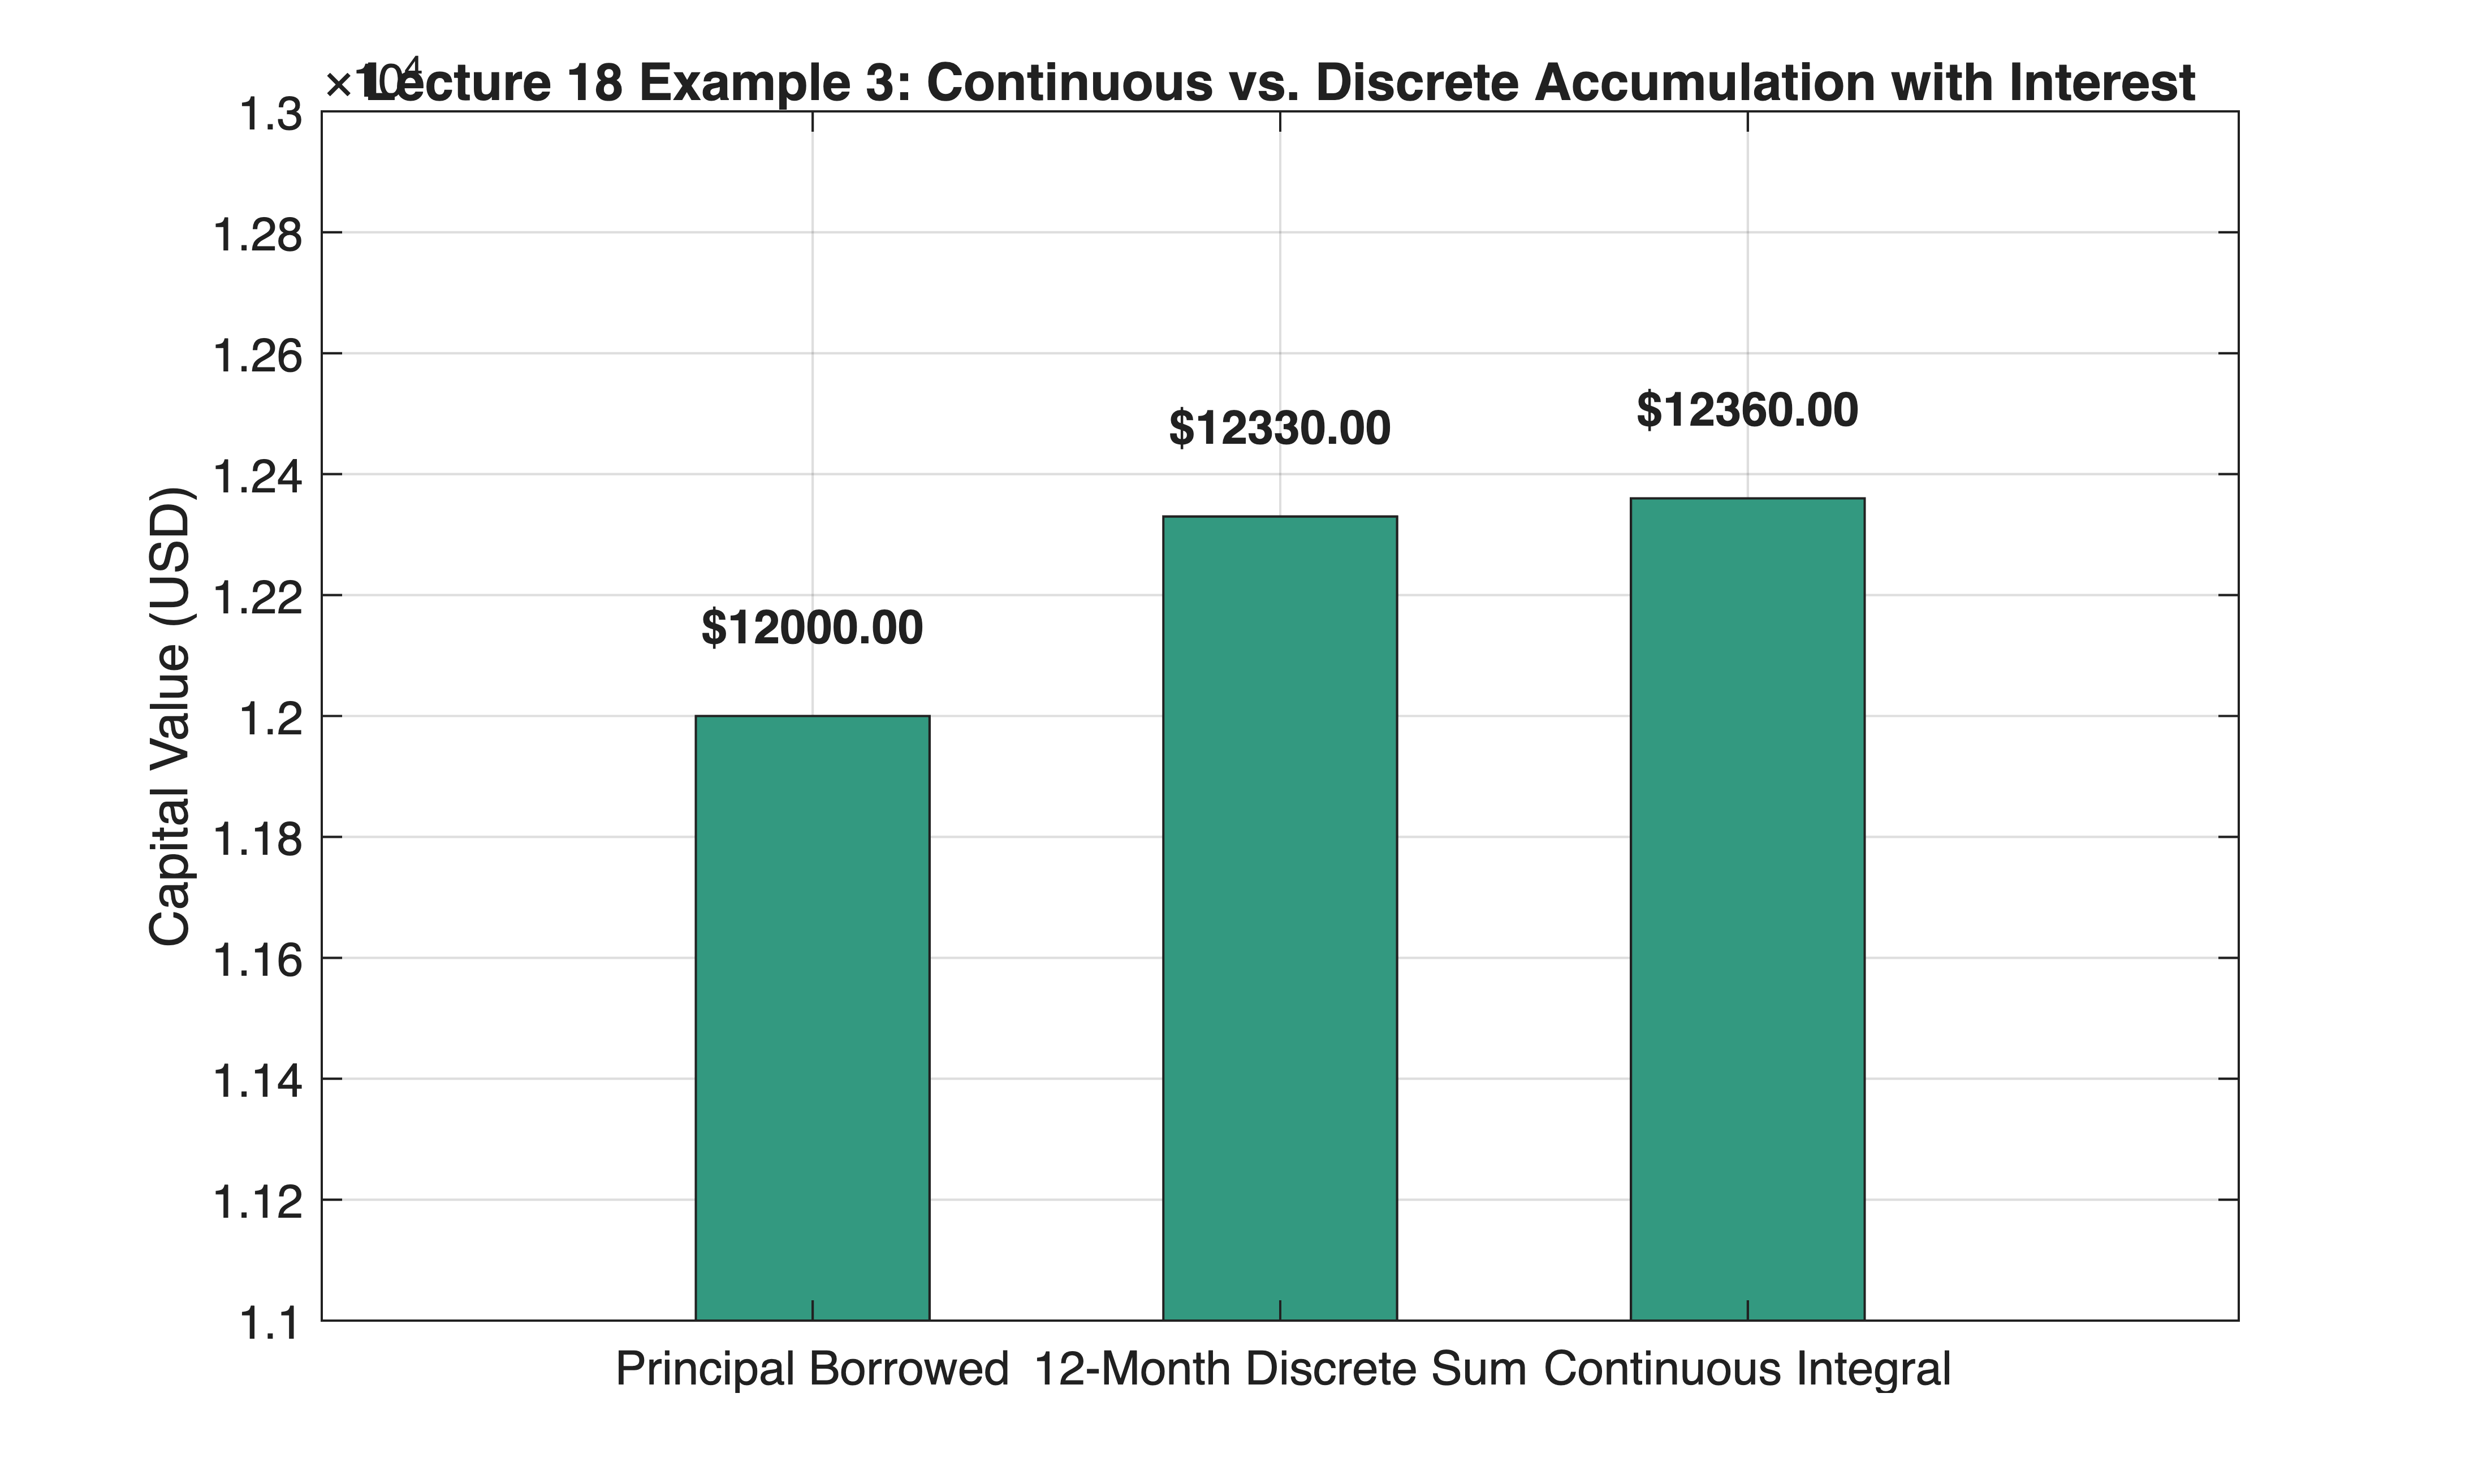

In [2]:


%% Part 2: Dynamic Accumulation of Debt with Interest (Example 3)
% Borrowing rate f(t) = 12000 (constant $12,000/year = $1,000/month)
% Interest rate r = 6% = 0.06/year over 1 year (T = 1.0)
f_rate = 12000.0;
r_interest = 0.06;
T_duration = 1.0;


% Exact Continuous Integral: \int_0^1 f(t) * (1 + r*(1 - t)) dt
% = f_rate * [ t + r*(t - t^2/2) ] from 0 to 1 = f_rate * (1 + 0.5*r)
exact_total_owed = f_rate * (1.0 + 0.5 * r_interest);
exact_principal = f_rate * T_duration;


% Discrete Monthly Accumulation (n = 12, Delta t = 1/12)
n_months = 12;
dt_month = T_duration / n_months;
t_months = (1:n_months) * dt_month;
% Principal borrowed per month = f_rate * dt_month
discrete_owed = sum(f_rate * (1.0 + r_interest * (1.0 - t_months)) * dt_month);


figure('Color', 'w', 'Position', [150, 150, 700, 420]);
bar_data = [exact_principal, discrete_owed, exact_total_owed];
bar_handles = bar(bar_data, 0.5, 'FaceColor', [0.2, 0.6, 0.5]);
set(gca, 'XTickLabel', {'Principal Borrowed', '12-Month Discrete Sum', 'Continuous Integral'});
ylabel('Capital Value (USD)');
title('Lecture 18 Example 3: Continuous vs. Discrete Accumulation with Interest');
grid on;
ylim([11000, 13000]);


text(1, exact_principal + 150, sprintf('$%.2f', exact_principal), 'HorizontalAlignment', 'center', 'FontWeight', 'bold');
text(2, discrete_owed + 150, sprintf('$%.2f', discrete_owed), 'HorizontalAlignment', 'center', 'FontWeight', 'bold');
text(3, exact_total_owed + 150, sprintf('$%.2f', exact_total_owed), 'HorizontalAlignment', 'center', 'FontWeight', 'bold');